# Détection explicable du blanchiment d'argent (SAML-D)

Approche centrale **non supervisée**, modèle supervisé en point de comparaison.
Les décisions et leurs justifications sont dans `docs/CHOIX.md`.

**Règle de période** (`docs/CHOIX.md`, section 16) : les chiffres descriptifs globaux portent
sur tout le jeu ; les graphiques qui guident le choix des variables portent sur la **période
d'entraînement seulement**, pour ne pas regarder le futur. Le sous-titre de chaque graphique
indique sa période.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter, MultipleLocator

from aml_xai import eda
from aml_xai.config import REPORTS_DIR, TARGET, TIMESTAMP, TRAIN_FRAC, VALID_FRAC
from aml_xai.data import load_training_period, load_transactions, train_cutoff

%matplotlib inline

BLEU, ORANGE = "#2a78d6", "#eb6834"  # transactions normales, blanchiment
ENCRE, ENCRE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "font.size": 10, "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE_2, "text.color": ENCRE,
    "xtick.color": ENCRE_2, "ytick.color": ENCRE_2, "xtick.bottom": False, "ytick.left": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRILLE,
    "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def fr(x, decimales=2):
    """Nombre au format français : virgule décimale, espace pour les milliers."""
    return f"{x:,.{decimales}f}".replace(",", "\u00a0").replace(".", ",")


def date_fr(t):
    return pd.Timestamp(t).strftime("%d/%m/%Y")


def note(texte):
    """Commentaire dont les chiffres viennent du calcul, jamais d'une recopie."""
    display(Markdown(texte))


LEGENDE_TAUX = "pointillés : taux moyen de la période · traits noirs : intervalle à 95 %"


def titres(fig, titre, periode, legende=""):
    fig.text(0.01, 1.0, titre, fontsize=13, fontweight="bold", va="bottom")
    sous_titre = f"Période : {periode}" + (f" · {legende}" if legende else "")
    fig.text(0.01, 0.985, sous_titre, fontsize=9, color=ENCRE_2, va="top")


def barres_taux(ax, table, taux_periode):
    """Barres horizontales triées : taux, intervalle à 95 %, nombre de cas."""
    t = table.sort_values("taux_pct")
    y = np.arange(len(t))
    ax.barh(y, t["taux_pct"], height=0.62, color=ORANGE)
    erreurs = [t["taux_pct"] - t["ic_bas_pct"], t["ic_haut_pct"] - t["taux_pct"]]
    ax.errorbar(t["taux_pct"], y, xerr=erreurs, fmt="none", ecolor=ENCRE, elinewidth=1, capsize=2)
    for i, (haut, cas) in enumerate(zip(t["ic_haut_pct"], t["blanchiment"])):
        ax.annotate(f"{fr(cas, 0)} cas", (haut, i), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=8, color=ENCRE_2, zorder=5,
                    bbox={"facecolor": FOND, "edgecolor": "none", "pad": 0.8})
    ax.axvline(taux_periode, color=ENCRE_2, linewidth=1, linestyle="--")
    ax.set_yticks(y, t.index)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.16)
    ax.set_xlabel("Taux de blanchiment (%)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 2)))

## 1. Données

### 1.1 Chiffres descriptifs globaux

Ces chiffres portent sur **tout le jeu**. Ils décrivent les données sans guider le choix des
variables. Ils viennent de `reports/qualite_donnees.json`, produit par `scripts/check_quality.py`.

In [2]:
qualite = json.loads((REPORTS_DIR / "qualite_donnees.json").read_text(encoding="utf-8"))
temps = load_transactions([TIMESTAMP, TARGET])
coupure_train = train_cutoff(temps[TIMESTAMP], TRAIN_FRAC)
coupure_valid = train_cutoff(temps[TIMESTAMP], TRAIN_FRAC + VALID_FRAC)

pd.DataFrame(
    {
        "Valeur": [
            fr(qualite["lignes"], 0),
            fr(len(qualite["colonnes"]), 0),
            f"{date_fr(qualite['periode'][0])} → {date_fr(qualite['periode'][1])}",
            fr(qualite["nb_blanchiment"], 0),
            f"{fr(qualite['taux_blanchiment_pct'], 4)} %",
            f"{qualite['nb_typologies']} ({qualite['nb_typologies_normales']} normales, "
            f"{qualite['nb_typologies_suspectes']} suspectes)",
            fr(qualite["nb_comptes_emetteurs"], 0),
            fr(qualite["nb_comptes_destinataires"], 0),
            fr(sum(qualite["valeurs_manquantes"].values()), 0),
            fr(qualite["doublons_hors_identifiant"], 0),
        ]
    },
    index=[
        "Transactions", "Colonnes après conversion", "Période (jeu complet)", "Cas de blanchiment",
        "Taux de blanchiment", "Typologies", "Comptes émetteurs", "Comptes destinataires",
        "Valeurs manquantes", "Doublons",
    ],
)

,Valeur
Transactions,9 504 852
Colonnes après conversion,12
Période (jeu complet),07/10/2022 → 23/08/2023
Cas de blanchiment,9 873
Taux de blanchiment,"0,1039 %"
Typologies,"28 (11 normales, 17 suspectes)"
Comptes émetteurs,292 715
Comptes destinataires,652 266
Valeurs manquantes,0
Doublons,0


In [3]:
bornes = [temps[TIMESTAMP].min(), coupure_train, coupure_valid, temps[TIMESTAMP].max()]
masques = [
    temps[TIMESTAMP] < coupure_train,
    (temps[TIMESTAMP] >= coupure_train) & (temps[TIMESTAMP] < coupure_valid),
    temps[TIMESTAMP] >= coupure_valid,
]
pd.DataFrame(
    {
        "Début": [date_fr(b) for b in bornes[:3]],
        "Fin": [date_fr(b) for b in bornes[1:]],
        "Lignes": [fr(m.sum(), 0) for m in masques],
        "Part": [f"{fr(100 * m.mean(), 1)} %" for m in masques],
    },
    index=["Entraînement", "Validation", "Test"],
)

,Début,Fin,Lignes,Part
Entraînement,07/10/2022,16/04/2023,5 702 911,"60,0 %"
Validation,16/04/2023,19/06/2023,1 900 970,"20,0 %"
Test,19/06/2023,23/08/2023,1 900 971,"20,0 %"


### 1.2 Évolution du taux dans le temps

Ce graphique, demandé par le module 1, porte sur le **jeu complet** : il décrit la stabilité du
phénomène entre les trois périodes. Il ne sert pas à choisir des variables ni des réglages.

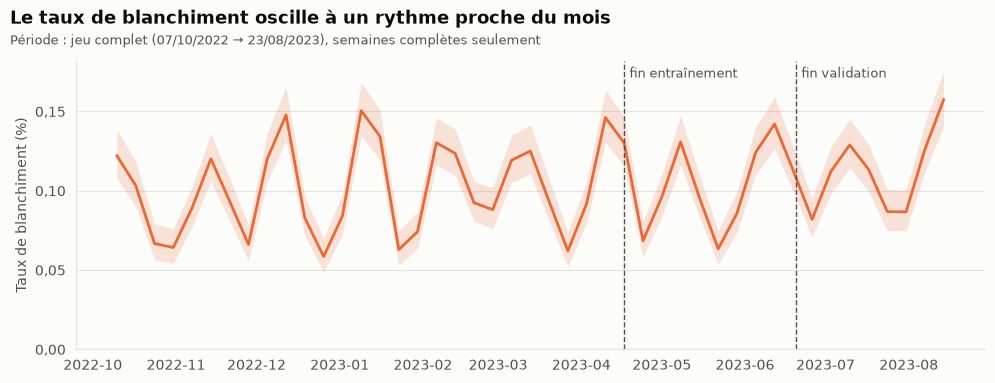

Taux hebdomadaire de **0,059 %** à **0,157 %** sur 45 semaines complètes. La bande colorée est l'intervalle de confiance à 95 %. Le motif se répète dans les trois périodes ; il est mesuré sur la période d'entraînement seule en 1.7.

In [4]:
semaines = eda.rate_by_week(temps)
fig, ax = plt.subplots(figsize=(10, 3.6))
titres(fig, "Le taux de blanchiment oscille à un rythme proche du mois",
       f"jeu complet ({date_fr(bornes[0])} → {date_fr(bornes[-1])}), semaines complètes seulement")
ax.fill_between(semaines.index, semaines["ic_bas_pct"], semaines["ic_haut_pct"], color=ORANGE,
                alpha=0.18, linewidth=0)
ax.plot(semaines.index, semaines["taux_pct"], color=ORANGE, linewidth=2)
for coupure, nom in ((coupure_train, "fin entraînement"), (coupure_valid, "fin validation")):
    ax.axvline(coupure, color=ENCRE_2, linewidth=1, linestyle="--")
    ax.annotate(nom, (coupure, 1), xycoords=("data", "axes fraction"), xytext=(4, -4),
                textcoords="offset points", fontsize=9, color=ENCRE_2, va="top")
ax.set_ylim(bottom=0)
ax.set_ylabel("Taux de blanchiment (%)")
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 2)))
ax.grid(axis="x", visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

note(
    f"Taux hebdomadaire de **{fr(semaines['taux_pct'].min(), 3)} %** à "
    f"**{fr(semaines['taux_pct'].max(), 3)} %** sur {len(semaines)} semaines complètes. "
    "La bande colorée est l'intervalle de confiance à 95 %. Le motif se répète dans les trois "
    "périodes ; il est mesuré sur la période d'entraînement seule en 1.7."
)

### 1.3 Chargement de la période d'entraînement

Tous les graphiques suivants utilisent `train`, chargé par `load_training_period` : seules les
lignes **strictement antérieures à la coupure des 60 %** sont lues.

In [5]:
del temps
colonnes = [TIMESTAMP, "Amount", "Payment_currency", "Received_currency", "Sender_bank_location",
            "Receiver_bank_location", "Payment_type", TARGET, "Laundering_type"]
train, coupure = load_training_period(colonnes)
PERIODE_TRAIN = f"entraînement seulement ({date_fr(train[TIMESTAMP].min())} → {date_fr(coupure)})"
taux_train = 100 * train[TARGET].mean()
assert train[TIMESTAMP].max() < coupure

note(
    f"**Entraînement** : {fr(len(train), 0)} lignes, {fr(train[TARGET].sum(), 0)} cas de blanchiment, "
    f"taux de {fr(taux_train, 4)} %. La ligne pointillée des graphiques suivants marque ce taux."
)

**Entraînement** : 5 702 911 lignes, 5 742 cas de blanchiment, taux de 0,1007 %. La ligne pointillée des graphiques suivants marque ce taux.

### 1.4 Distribution des montants par classe

Chaque courbe montre la part de sa classe par tranche de montant. L'axe horizontal est
logarithmique : chaque graduation multiplie le montant par 10.

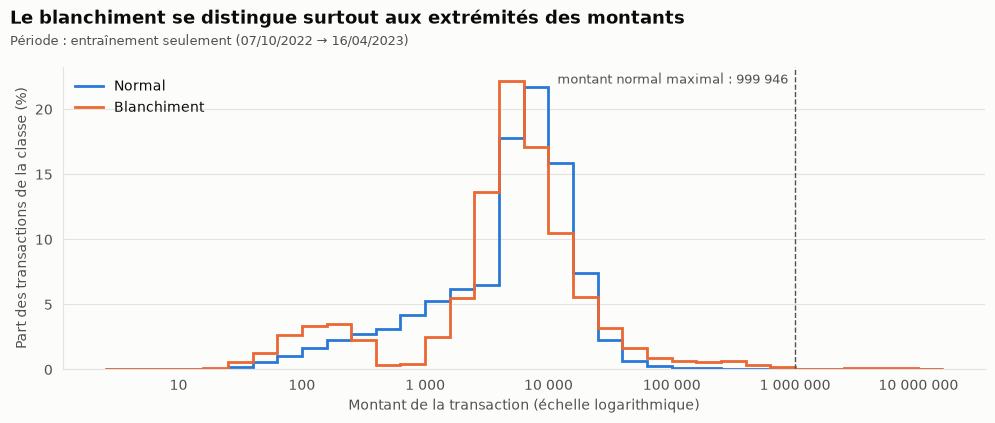

Montant médian : **6 118** pour les transactions normales, **5 215** pour le blanchiment. Aucune transaction normale ne dépasse **999 946,47**, alors que **26 cas de blanchiment** vont au-delà. Ces 26 cas appartiennent tous à la typologie **Over-Invoicing**, qui compte 26 cas sur cette période. Ce plafond net ressemble à un **artefact du générateur** : dans la réalité, de très gros virements légitimes existent. La détection de cette typologie par le montant sera à discuter.

In [6]:
parts = eda.amount_shares(train)
parts = parts[(parts["normal_pct"] > 0) | (parts["blanchiment_pct"] > 0)]
bords = np.append(parts["borne_basse"].to_numpy(), parts["borne_haute"].iloc[-1])
est_blanchiment = train[TARGET] == 1
max_normal = train.loc[~est_blanchiment, "Amount"].max()
au_dessus = train[est_blanchiment & (train["Amount"] > max_normal)]
cas_au_dessus = len(au_dessus)
types_au_dessus = au_dessus["Laundering_type"].astype(str).unique()
cas_type = int((train["Laundering_type"] == types_au_dessus[0]).sum())
assert len(types_au_dessus) == 1

fig, ax = plt.subplots(figsize=(10, 4))
titres(fig, "Le blanchiment se distingue surtout aux extrémités des montants", PERIODE_TRAIN)
ax.stairs(parts["normal_pct"], bords, color=BLEU, linewidth=2, label="Normal")
ax.stairs(parts["blanchiment_pct"], bords, color=ORANGE, linewidth=2, label="Blanchiment")
ax.axvline(max_normal, color=ENCRE_2, linewidth=1, linestyle="--")
ax.annotate(f"montant normal maximal : {fr(max_normal, 0)}", (max_normal, 1),
            xycoords=("data", "axes fraction"), xytext=(-5, -4), textcoords="offset points",
            fontsize=9, color=ENCRE_2, va="top", ha="right")
ax.set_xscale("log")
ax.set_xlabel("Montant de la transaction (échelle logarithmique)")
ax.set_ylabel("Part des transactions de la classe (%)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 0)))
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

medianes = train.groupby(TARGET)["Amount"].median()
note(
    f"Montant médian : **{fr(medianes[0], 0)}** pour les transactions normales, "
    f"**{fr(medianes[1], 0)}** pour le blanchiment. "
    f"Aucune transaction normale ne dépasse **{fr(max_normal, 2)}**, alors que "
    f"**{cas_au_dessus} cas de blanchiment** vont au-delà. "
    f"Ces {cas_au_dessus} cas appartiennent tous à la typologie **{types_au_dessus[0]}**, qui compte "
    f"{cas_type} cas sur cette période. "
    "Ce plafond net ressemble à un **artefact du générateur** : dans la réalité, de très gros "
    "virements légitimes existent. La détection de cette typologie par le montant sera à discuter."
)

### 1.5 Taux par heure

Le volume et le taux sont sur deux graphiques séparés, car ils n'ont pas la même échelle.

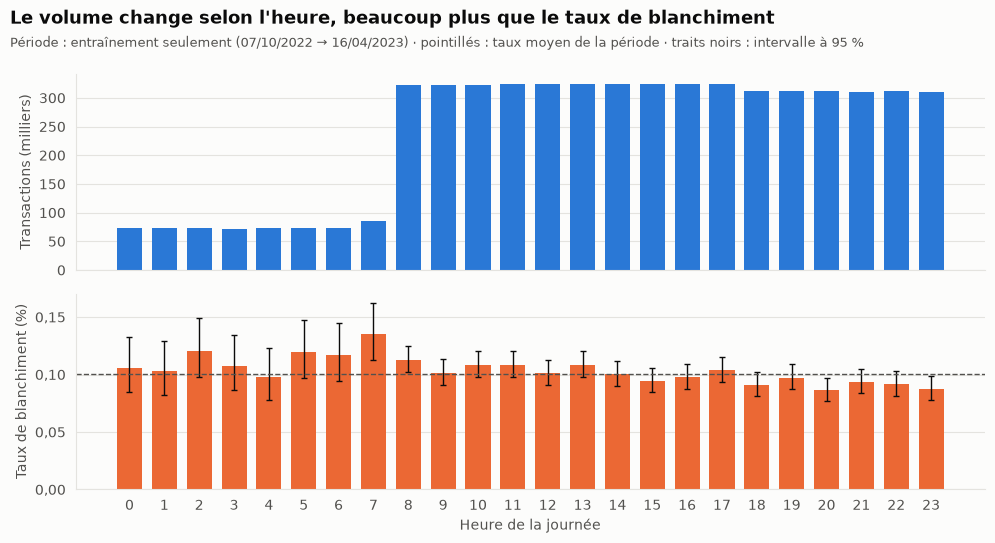

Le volume passe de 72 323 à 324 982 transactions par tranche horaire, avec des paliers nets qui rappellent un jeu simulé. Le taux varie de 0,086 % (20 h) à 0,135 % (7 h) : l'heure n'apporte qu'un signal faible.

In [7]:
heures = eda.rate_by_hour(train)
fig, (haut, bas) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
titres(fig, "Le volume change selon l'heure, beaucoup plus que le taux de blanchiment", PERIODE_TRAIN,
       LEGENDE_TAUX)
haut.bar(heures.index, heures["transactions"] / 1000, width=0.72, color=BLEU)
haut.set_ylabel("Transactions (milliers)")
haut.grid(axis="x", visible=False)
bas.bar(heures.index, heures["taux_pct"], width=0.72, color=ORANGE)
bas.errorbar(heures.index, heures["taux_pct"], fmt="none", ecolor=ENCRE, elinewidth=1, capsize=2,
             yerr=[heures["taux_pct"] - heures["ic_bas_pct"], heures["ic_haut_pct"] - heures["taux_pct"]])
bas.axhline(taux_train, color=ENCRE_2, linewidth=1, linestyle="--")
bas.set_ylabel("Taux de blanchiment (%)")
bas.set_xlabel("Heure de la journée")
bas.set_xticks(range(0, 24))
bas.yaxis.set_major_locator(MultipleLocator(0.05))
bas.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 2)))
bas.grid(axis="x", visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

note(
    f"Le volume passe de {fr(heures['transactions'].min(), 0)} à "
    f"{fr(heures['transactions'].max(), 0)} transactions par tranche horaire, avec des paliers nets "
    "qui rappellent un jeu simulé. "
    f"Le taux varie de {fr(heures['taux_pct'].min(), 3)} % ({heures['taux_pct'].idxmin()} h) à "
    f"{fr(heures['taux_pct'].max(), 3)} % ({heures['taux_pct'].idxmax()} h) : l'heure n'apporte qu'un "
    "signal faible."
)

### 1.6 Taux par jour de la semaine

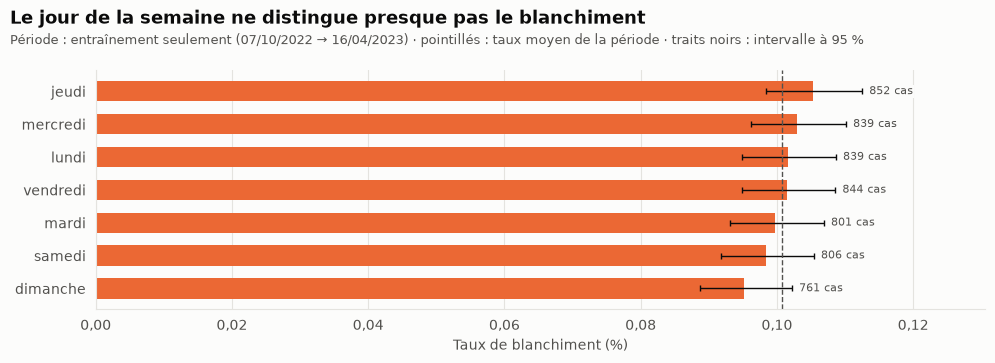

Taux de 0,095 % (dimanche) à 0,105 % (jeudi). Tous les intervalles à 95 % se recouvrent : ces écarts sont compatibles avec le hasard.

In [8]:
jours = eda.rate_by_weekday(train)
fig, ax = plt.subplots(figsize=(10, 3.4))
titres(fig, "Le jour de la semaine ne distingue presque pas le blanchiment", PERIODE_TRAIN, LEGENDE_TAUX)
barres_taux(ax, jours, taux_train)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

recouvrement = jours["ic_bas_pct"].max() <= jours["ic_haut_pct"].min()
note(
    f"Taux de {fr(jours['taux_pct'].min(), 3)} % ({jours['taux_pct'].idxmin()}) à "
    f"{fr(jours['taux_pct'].max(), 3)} % ({jours['taux_pct'].idxmax()}). "
    + ("Tous les intervalles à 95 % se recouvrent : ces écarts sont compatibles avec le hasard."
       if recouvrement else
       "Certains intervalles à 95 % ne se recouvrent pas, mais l'écart reste faible.")
)

### 1.7 Taux par jour du mois

Cette section mesure sur la période d'entraînement le rythme vu en 1.2.

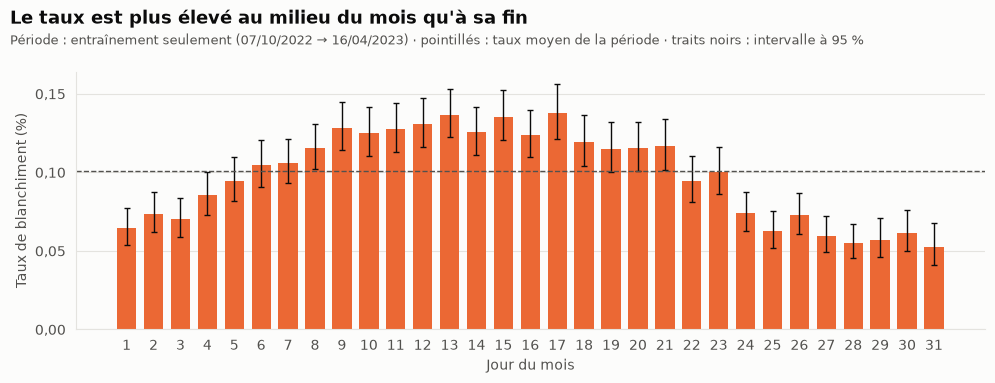

Le taux va de 0,053 % (jour 31) à 0,138 % (jour 17), soit un facteur 2,6. Leurs intervalles à 95 % ne se recouvrent pas : l'écart n'est pas dû au hasard. Aucune raison métier évidente ne l'explique, et sa régularité suggère un **effet du générateur**. Une variable « jour du mois » apprendrait cet effet plutôt qu'un comportement de blanchiment.

In [9]:
jours_mois = eda.rate_by_day_of_month(train)
fig, ax = plt.subplots(figsize=(10, 3.6))
titres(fig, "Le taux est plus élevé au milieu du mois qu'à sa fin", PERIODE_TRAIN, LEGENDE_TAUX)
ax.bar(jours_mois.index, jours_mois["taux_pct"], width=0.72, color=ORANGE)
ax.errorbar(jours_mois.index, jours_mois["taux_pct"], fmt="none", ecolor=ENCRE, elinewidth=1, capsize=2,
            yerr=[jours_mois["taux_pct"] - jours_mois["ic_bas_pct"],
                  jours_mois["ic_haut_pct"] - jours_mois["taux_pct"]])
ax.axhline(taux_train, color=ENCRE_2, linewidth=1, linestyle="--")
ax.set_xlabel("Jour du mois")
ax.set_ylabel("Taux de blanchiment (%)")
ax.set_xticks(range(1, 32))
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 2)))
ax.grid(axis="x", visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

jour_max, jour_min = jours_mois["taux_pct"].idxmax(), jours_mois["taux_pct"].idxmin()
note(
    f"Le taux va de {fr(jours_mois.loc[jour_min, 'taux_pct'], 3)} % (jour {jour_min}) à "
    f"{fr(jours_mois.loc[jour_max, 'taux_pct'], 3)} % (jour {jour_max}), soit un facteur "
    f"{fr(jours_mois.loc[jour_max, 'taux_pct'] / jours_mois.loc[jour_min, 'taux_pct'], 1)}. "
    "Leurs intervalles à 95 % "
    + ("ne se recouvrent pas" if jours_mois.loc[jour_min, 'ic_haut_pct'] < jours_mois.loc[jour_max, 'ic_bas_pct']
       else "se recouvrent")
    + " : l'écart n'est pas dû au hasard. Aucune raison métier évidente ne l'explique, et sa "
    "régularité suggère un **effet du générateur**. Une variable « jour du mois » apprendrait "
    "cet effet plutôt qu'un comportement de blanchiment."
)

### 1.8 Taux par type de paiement

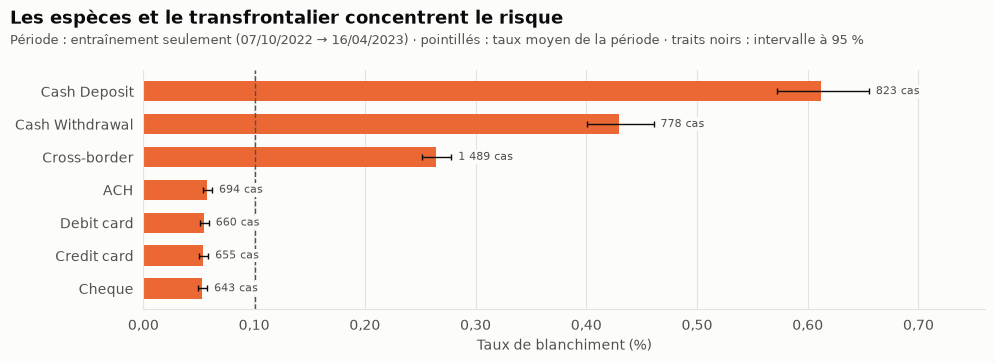

**Cash Deposit** atteint 0,61 %, soit 11,5 fois le taux le plus bas (Cheque, 0,05 %). Le type de paiement est une variable utile.

In [10]:
paiements = eda.rate_by(train, "Payment_type")
fig, ax = plt.subplots(figsize=(10, 3.4))
titres(fig, "Les espèces et le transfrontalier concentrent le risque", PERIODE_TRAIN, LEGENDE_TAUX)
barres_taux(ax, paiements, taux_train)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

note(
    f"**{paiements['taux_pct'].idxmax()}** atteint {fr(paiements['taux_pct'].max(), 2)} %, soit "
    f"{fr(paiements['taux_pct'].max() / paiements['taux_pct'].min(), 1)} fois le taux le plus bas "
    f"({paiements['taux_pct'].idxmin()}, {fr(paiements['taux_pct'].min(), 2)} %). "
    "Le type de paiement est une variable utile."
)

### 1.9 Taux par pays

Les barres d'erreur comptent ici : hors Royaume-Uni, chaque pays repose sur peu de cas.

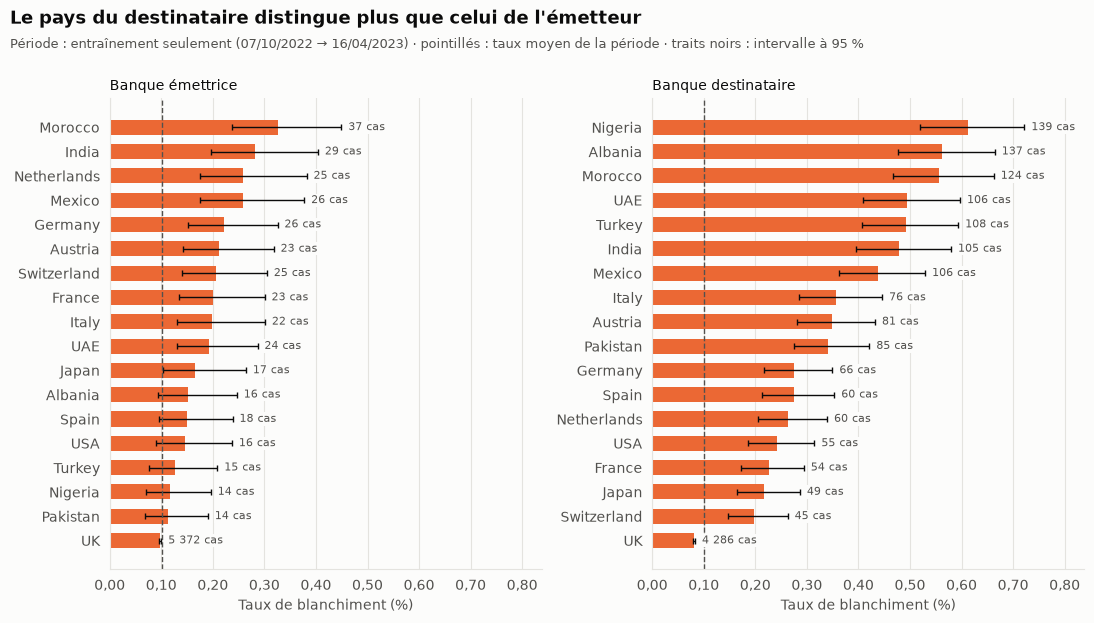

**96,7 %** des transactions partent du Royaume-Uni. Hors Royaume-Uni, les pays émetteurs ne comptent que 14 à 37 cas chacun : leur classement est peu fiable. Côté destinataire, **Nigeria** atteint 0,61 %.

Quand les deux pays diffèrent, le taux vaut 0,310 % contre 0,078 % sinon. Cette information recoupe le type de paiement : 99,95 % des transactions entre deux pays sont de type `Cross-border`.

In [11]:
emetteurs = eda.rate_by(train, "Sender_bank_location")
destinataires = eda.rate_by(train, "Receiver_bank_location")
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(11, 6), sharex=True)
titres(fig, "Le pays du destinataire distingue plus que celui de l'émetteur", PERIODE_TRAIN, LEGENDE_TAUX)
barres_taux(gauche, emetteurs, taux_train)
gauche.set_title("Banque émettrice", loc="left", fontsize=10)
barres_taux(droite, destinataires, taux_train)
droite.set_title("Banque destinataire", loc="left", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

part_uk = 100 * emetteurs.loc["UK", "transactions"] / len(train)
pays_differents = eda.rate_by(train, eda.location_differs(train))
transfrontalier = train["Payment_type"] == "Cross-border"
differents = eda.location_differs(train)
note(
    f"**{fr(part_uk, 1)} %** des transactions partent du Royaume-Uni. "
    f"Hors Royaume-Uni, les pays émetteurs ne comptent que {emetteurs.drop('UK')['blanchiment'].min()} à "
    f"{emetteurs.drop('UK')['blanchiment'].max()} cas chacun : leur classement est peu fiable. "
    f"Côté destinataire, **{destinataires['taux_pct'].idxmax()}** atteint "
    f"{fr(destinataires['taux_pct'].max(), 2)} %.\n\n"
    f"Quand les deux pays diffèrent, le taux vaut {fr(pays_differents.loc[True, 'taux_pct'], 3)} % contre "
    f"{fr(pays_differents.loc[False, 'taux_pct'], 3)} % sinon. "
    f"Cette information recoupe le type de paiement : {fr(100 * transfrontalier[differents].mean(), 2)} % "
    "des transactions entre deux pays sont de type `Cross-border`."
)

### 1.10 Taux par devise

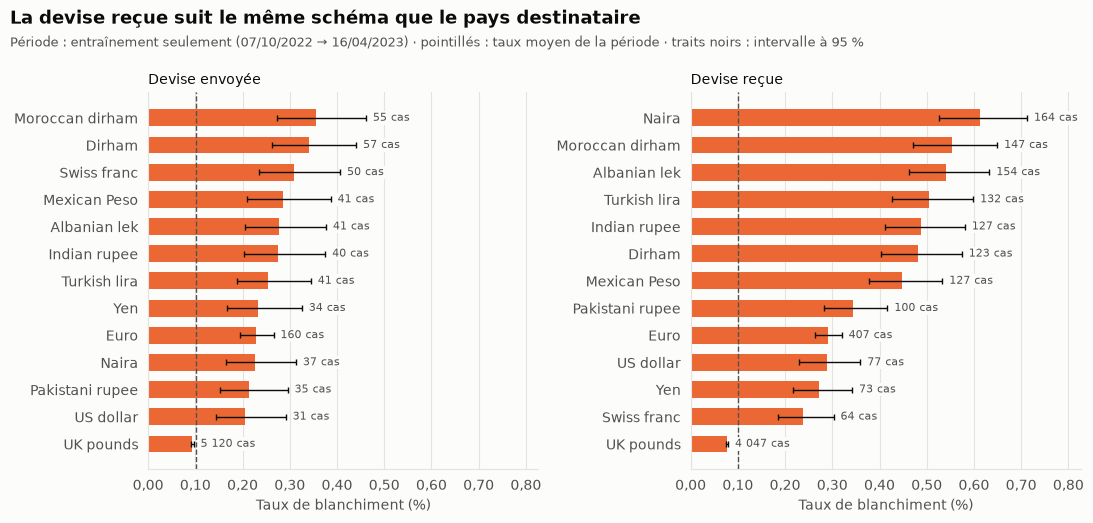

Quand la devise envoyée diffère de la devise reçue, le taux vaut **0,322 %** contre 0,072 % sinon.

In [12]:
envoyees = eda.rate_by(train, "Payment_currency")
recues = eda.rate_by(train, "Received_currency")
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(11, 5), sharex=True)
titres(fig, "La devise reçue suit le même schéma que le pays destinataire", PERIODE_TRAIN, LEGENDE_TAUX)
barres_taux(gauche, envoyees, taux_train)
gauche.set_title("Devise envoyée", loc="left", fontsize=10)
barres_taux(droite, recues, taux_train)
droite.set_title("Devise reçue", loc="left", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

devises = eda.rate_by(train, eda.currency_differs(train))
note(
    f"Quand la devise envoyée diffère de la devise reçue, le taux vaut "
    f"**{fr(devises.loc[True, 'taux_pct'], 3)} %** contre {fr(devises.loc[False, 'taux_pct'], 3)} % sinon."
)

### 1.11 Typologies de blanchiment

La typologie sert uniquement à l'analyse : `Laundering_type` n'entre jamais dans un modèle, car
ses valeurs `Normal_…` révèlent l'étiquette (`docs/CHOIX.md`, section 2).

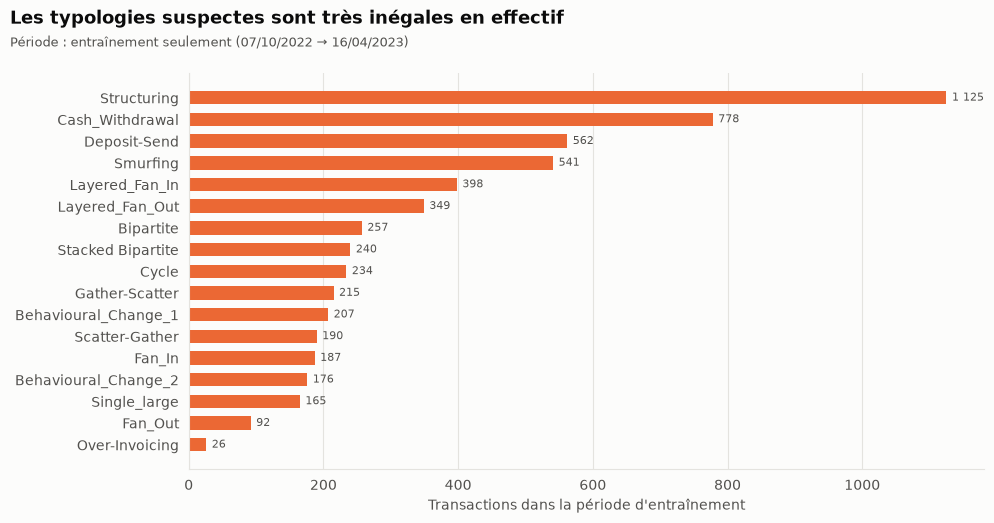

,transactions,blanchiment,montant_median
Laundering_type,,,
Normal_Small_Fan_Out,2091506,0,2 209
Normal_Fan_Out,1391910,0,8 424
Normal_Fan_In,1271035,0,8 989
Normal_Group,317590,0,3 435
Normal_Cash_Withdrawal,183880,0,139
Normal_Cash_Deposits,133629,0,1 759
Normal_Periodical,126442,0,4 446
Normal_Mutual,74856,0,27 460
Normal_Plus_Mutual,68883,0,15 561


In [13]:
typologies = eda.typology_table(train)
suspectes = typologies[typologies["blanchiment"] == 1].sort_values("transactions")
fig, ax = plt.subplots(figsize=(10, 5))
titres(fig, "Les typologies suspectes sont très inégales en effectif", PERIODE_TRAIN)
y = np.arange(len(suspectes))
ax.barh(y, suspectes["transactions"], height=0.62, color=ORANGE)
for i, n in enumerate(suspectes["transactions"]):
    ax.annotate(fr(n, 0), (n, i), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=8, color=ENCRE_2)
ax.set_yticks(y, suspectes.index)
ax.set_xlabel("Transactions dans la période d'entraînement")
ax.grid(axis="y", visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

typologies.assign(montant_median=typologies["montant_median"].map(lambda v: fr(v, 0)))

In [14]:
mediane_normale = train.loc[~est_blanchiment, "Amount"].median()
proches = suspectes[suspectes["montant_median"].between(mediane_normale / 3, mediane_normale * 3)]
note(
    f"**{len(proches)} typologies suspectes sur {len(suspectes)}** ont un montant médian à moins d'un "
    f"facteur 3 de la médiane des transactions normales ({fr(mediane_normale, 0)}). "
    "Le montant seul ne suffira donc pas : il faudra des variables de comportement des comptes. "
    "Les typologies les plus rares auront très peu de cas en validation et en test : leurs résultats "
    "seront toujours présentés avec les effectifs."
)

**13 typologies suspectes sur 17** ont un montant médian à moins d'un facteur 3 de la médiane des transactions normales (6 118). Le montant seul ne suffira donc pas : il faudra des variables de comportement des comptes. Les typologies les plus rares auront très peu de cas en validation et en test : leurs résultats seront toujours présentés avec les effectifs.

### 1.12 Pistes pour l'étape 2

Ce sont des **hypothèses** tirées de la période d'entraînement, pas des résultats. Les modèles
trancheront.

- **À garder** : montant (en logarithme), type de paiement, pays et devise du destinataire,
  indicateur « devises différentes ».
- **Redondance à vérifier** : « pays différents » recoupe presque entièrement `Cross-border`.
- **Signal faible attendu** : heure et jour de la semaine, demandés par le sujet ; à garder pour
  le vérifier par la mesure.
- **À ne pas utiliser (à confirmer)** : le jour du mois, dont l'effet semble venir du générateur.
- **À discuter à l'oral** : le plafond des montants normaux, probable artefact du générateur, et
  la typologie qui le dépasse.
- **Limite de cette exploration** : elle regarde chaque transaction seule. Les schémas en réseau
  (cycles, éventails) ne se voient qu'avec les variables par compte de l'étape 2.